# Balanced + Feature-Augmented CICIoT2023 — DNN, 5-Seed Evaluation

## 1. Environment and reproducibility

In [1]:
import json
import platform
import joblib
import sklearn
# Global reproducibility setup
import os
import random
import numpy as np
import tensorflow as tf

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print("Global seed set to:", SEED)

Global seed set to: 42


In [2]:
import pandas as pd
import numpy as np
import sklearn, os
from sklearn.preprocessing import StandardScaler # RobustScaler
import matplotlib.pyplot as plt  # for plotting
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix
from sklearn.metrics import roc_auc_score, roc_curve, auc
from tensorflow.keras.optimizers import Adam

from sklearn.preprocessing import LabelEncoder
import seaborn as sns 
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report
import time

## 2. Data preprocessing and feature augmentation

The cells below retain the original preprocessing order and diagnostic outputs.

### Directly clean Augmented data 

In [3]:
# ============================================================
# Load the augmented partitions
train_data = pd.read_csv(
    r"/kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/CICIoT2023_Augmented_Train.csv"
)

validation_data = pd.read_csv(
    r"/kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/CICIoT2023_Augmented_Validation.csv"
)

test_data = pd.read_csv(
    r"/kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/CICIoT2023_Augmented_Test.csv"
)


print(f"Training data:   {train_data.shape}")
print(f"Validation data: {validation_data.shape}")
print(f"Test data:       {test_data.shape}")

display(train_data.head())

Training data:   (354737, 36)
Validation data: (118246, 36)
Test data:       (118246, 36)


,flow_duration,Header_Length,Protocol Type,Duration,Rate,Drate,fin_flag_number,syn_flag_number,psh_flag_number,ack_flag_number,...,Max,AVG,Tot size,IAT,Covariance,Variance,IF_Anomaly_Score,AE_Anomaly_Score,SUOD_Anomaly_Score,label
0,0.244612,38791.0,17.00,64.00,3202.228500,0.0,0.0,0.0,0.0,0.0,...,50.00,50.00000,50.00,83102420.0,0.000000,0.00,0.275168,0.004453,-0.277339,DDoS
1,0.014093,5675.0,17.00,64.00,8785.439000,0.0,0.0,0.0,0.0,0.0,...,50.00,50.00000,50.00,83123740.0,0.000000,0.00,0.283322,0.004197,-0.291433,DDoS
2,0.000000,0.0,47.00,64.00,218.863710,0.0,0.0,0.0,0.0,0.0,...,592.00,592.00000,592.00,83698550.0,0.000000,0.00,0.161012,0.083652,0.648249,Mirai
3,0.000000,54.0,6.00,64.00,3.887012,0.0,0.0,0.0,0.0,0.0,...,54.00,54.00000,54.00,83064136.0,0.000000,0.00,0.319291,0.000523,-0.766263,DDoS
4,0.000000,0.0,0.99,63.36,5.231067,0.0,0.0,0.0,0.0,0.0,...,43.98,42.13838,42.18,83150650.0,2.315749,0.11,0.216951,0.004651,0.238320,DDoS


In [4]:
# ============================================================
# Dataset validation + feature-ablation configuration
# ============================================================

# Name of the target column used throughout the notebook.
LABEL_COLUMN = "label"

# ------------------------------------------------------------
# Anomaly-score features used by the FA configuration
# ------------------------------------------------------------
ANOMALY_FEATURES = [
    "IF_Anomaly_Score",
    "AE_Anomaly_Score",
    "SUOD_Anomaly_Score",
]

# ============================================================
# Select the ablation configuration
# ============================================================

# Change ONLY this line when running a different ablation.
#
# Available configurations:
#
# "Full_FA"
#     Original traffic features
#     + IF_Anomaly_Score
#     + AE_Anomaly_Score
#     + SUOD_Anomaly_Score
#
# "No_FA"
#     Original traffic features only.
#     All three anomaly-score features are removed.
#
# "IF_only"
#     Original traffic features
#     + IF_Anomaly_Score
#
# "AE_only"
#     Original traffic features
#     + AE_Anomaly_Score
#
# "SUOD_only"
#     Original traffic features
#     + SUOD_Anomaly_Score

ABLATION_MODE = "Full_FA"

# ============================================================
# Validate the originally loaded augmented datasets
# ============================================================

# The same train, validation, and test partitions are used for
# every ablation configuration. Only the selected anomaly-score
# columns are removed. Samples, labels, and split membership
# therefore remain identical across configurations.

for dataset_name, dataset in {
    "Training": train_data,
    "Validation": validation_data,
    "Test": test_data,
}.items():

    if LABEL_COLUMN not in dataset.columns:
        raise KeyError(
            f"'{LABEL_COLUMN}' was not found in the "
            f"{dataset_name} dataset."
        )

    missing_anomaly_features = [
        feature
        for feature in ANOMALY_FEATURES
        if feature not in dataset.columns
    ]

    if missing_anomaly_features:
        raise KeyError(
            f"{dataset_name} dataset is missing "
            f"the following anomaly-score features: "
            f"{missing_anomaly_features}"
        )

# ============================================================
# Determine which anomaly-score features should be removed
# ============================================================

if ABLATION_MODE == "Full_FA":

    # Keep all three anomaly-score features.
    features_to_drop = []

elif ABLATION_MODE == "No_FA":

    # Remove all three anomaly-score features.
    features_to_drop = [
        "IF_Anomaly_Score",
        "AE_Anomaly_Score",
        "SUOD_Anomaly_Score",
    ]

elif ABLATION_MODE == "IF_only":

    # Keep only the Isolation Forest anomaly score.
    features_to_drop = [
        "AE_Anomaly_Score",
        "SUOD_Anomaly_Score",
    ]

elif ABLATION_MODE == "AE_only":

    # Keep only the Autoencoder reconstruction score.
    features_to_drop = [
        "IF_Anomaly_Score",
        "SUOD_Anomaly_Score",
    ]

elif ABLATION_MODE == "SUOD_only":

    # Keep only the SUOD ensemble anomaly score.
    features_to_drop = [
        "IF_Anomaly_Score",
        "AE_Anomaly_Score",
    ]

else:
    raise ValueError(
        f"Unknown ABLATION_MODE: {ABLATION_MODE}. "
        "Use one of: Full_FA, No_FA, IF_only, "
        "AE_only, or SUOD_only."
    )

# ============================================================
# Apply the selected ablation
# ============================================================

# Only the selected anomaly-score columns are removed.
# No instances or labels are modified.

train_data = train_data.drop(
    columns=features_to_drop
).copy()

validation_data = validation_data.drop(
    columns=features_to_drop
).copy()

test_data = test_data.drop(
    columns=features_to_drop
).copy()

# ============================================================
# Rebuild the feature list after ablation
# ============================================================

feature_columns = [
    column
    for column in train_data.columns
    if column != LABEL_COLUMN
]

# ============================================================
# Validate feature consistency across all partitions
# ============================================================

validation_feature_columns = [
    column
    for column in validation_data.columns
    if column != LABEL_COLUMN
]

test_feature_columns = [
    column
    for column in test_data.columns
    if column != LABEL_COLUMN
]

if feature_columns != validation_feature_columns:
    raise ValueError(
        "Training and validation feature columns do not match "
        "after applying the ablation configuration."
    )

if feature_columns != test_feature_columns:
    raise ValueError(
        "Training and test feature columns do not match "
        "after applying the ablation configuration."
    )

# ============================================================
# Confirm which anomaly-score features remain
# ============================================================

kept_anomaly_features = [
    feature
    for feature in ANOMALY_FEATURES
    if feature in feature_columns
]

# ============================================================
# Print experiment summary
# ============================================================

print("=" * 60)
print("Feature-ablation configuration")
print("=" * 60)

print(f"Ablation mode: {ABLATION_MODE}")
print(f"Number of input features: {len(feature_columns)}")
print(f"Kept anomaly-score features: {kept_anomaly_features}")
print(f"Dropped anomaly-score features: {features_to_drop}")
print(f"Training instances: {len(train_data):,}")
print(f"Validation instances: {len(validation_data):,}")
print(f"Test instances: {len(test_data):,}")

print("=" * 60)


Feature-ablation configuration
Ablation mode: Full_FA
Number of input features: 35
Kept anomaly-score features: ['IF_Anomaly_Score', 'AE_Anomaly_Score', 'SUOD_Anomaly_Score']
Dropped anomaly-score features: []
Training instances: 354,737
Validation instances: 118,246
Test instances: 118,246


### Separate augmented features and multiclass labels

In [5]:
# import numpy as np

# from sklearn.preprocessing import LabelEncoder


# ============================================================
# Extract augmented feature matrices
# ============================================================
# feature_columns were defined in the validation cell.
# Selecting these columns preserves the training column order.
X_train = train_data[
    feature_columns
].copy()

X_val = validation_data[
    feature_columns
].copy()

X_test = test_data[
    feature_columns
].copy()


# ============================================================
# Validate numeric feature values
# ============================================================
for dataset_name, feature_data in {
    "Training": X_train,
    "Validation": X_val,
    "Test": X_test
}.items():

    non_numeric_columns = feature_data.select_dtypes(
        exclude=np.number
    ).columns.tolist()

    if non_numeric_columns:
        raise TypeError(
            f"{dataset_name} data contain non-numeric "
            f"features: {non_numeric_columns}"
        )

    if not np.isfinite(
        feature_data.to_numpy(dtype=np.float32)
    ).all():
        raise ValueError(
            f"{dataset_name} features contain missing "
            "or infinite values."
        )


# ============================================================
# Extract original multiclass labels
# ============================================================
y_train_original = (
    train_data[LABEL_COLUMN]
    .astype(str)
    .str.strip()
)

y_val_original = (
    validation_data[LABEL_COLUMN]
    .astype(str)
    .str.strip()
)

y_test_original = (
    test_data[LABEL_COLUMN]
    .astype(str)
    .str.strip()
)


print(f"Training features:   {X_train.shape}")
print(f"Validation features: {X_val.shape}")
print(f"Test features:       {X_test.shape}")

print(
    f"\nNumber of training classes: "
    f"{y_train_original.nunique()}"
)

display(y_train_original.value_counts())

Training features:   (354737, 35)
Validation features: (118246, 35)
Test features:       (118246, 35)

Number of training classes: 8


label
DDoS          258100
DoS            61405
Mirai          20231
Benign          8248
Spoofing        3729
Recon           2736
Web              188
BruteForce       100
Name: count, dtype: int64

#### Encode the multiclass labels

In [6]:
# ============================================================
# Fit the label encoder on training labels only
# ============================================================
label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(
    y_train_original
)


# ============================================================
# Check for unknown validation or test classes
# ============================================================
training_classes = set(
    label_encoder.classes_
)

unknown_validation_classes = (
    set(y_val_original.unique())
    - training_classes
)

unknown_test_classes = (
    set(y_test_original.unique())
    - training_classes
)

if unknown_validation_classes:
    raise ValueError(
        "Validation data contain classes that are absent "
        f"from training: {sorted(unknown_validation_classes)}"
    )

if unknown_test_classes:
    raise ValueError(
        "Test data contain classes that are absent "
        f"from training: {sorted(unknown_test_classes)}"
    )


# Transform validation and test labels using the same encoder
y_val = label_encoder.transform(
    y_val_original
)

y_test = label_encoder.transform(
    y_test_original
)


# ============================================================
# Display multiclass mapping
# ============================================================
print("Multiclass label mapping:")

for class_code, class_name in enumerate(
    label_encoder.classes_
):
    print(f"{class_code}: {class_name}")


number_of_classes = len(
    label_encoder.classes_
)

print(
    f"\nNumber of multiclass target classes: "
    f"{number_of_classes}"
)

Multiclass label mapping:
0: Benign
1: BruteForce
2: DDoS
3: DoS
4: Mirai
5: Recon
6: Spoofing
7: Web

Number of multiclass target classes: 8


#### Resample only the training set, then standardize the features

In [7]:
# Run once if imbalanced-learn is not installed:
# !pip install imbalanced-learn

from collections import Counter
from imblearn.over_sampling import SMOTE


# ============================================================
# Define the desired total number of training instances
# for the selected encoded classes after SMOTE
# ============================================================
target_class_counts = {
    0: 8248 + 1752,
    1: 100 + 9900,
    5: 2736 + 7264,
    6: 3729 + 6271,
    7: 188 + 9812,
}


# Validate the strategy against the encoded training labels.
training_distribution_before_smote = Counter(
    map(int, y_train)
)

unknown_target_codes = (
    set(target_class_counts)
    - set(training_distribution_before_smote)
)

if unknown_target_codes:
    raise ValueError(
        "SMOTE target codes are absent from the training set: "
        f"{sorted(unknown_target_codes)}"
    )

invalid_target_counts = {
    class_code: target_count
    for class_code, target_count in target_class_counts.items()
    if target_count < training_distribution_before_smote[class_code]
}

if invalid_target_counts:
    raise ValueError(
        "Each SMOTE target must be at least its original training "
        "count. Invalid targets: "
        f"{invalid_target_counts}"
    )


# ============================================================
# Fit and apply SMOTE to unstandardized training data only
# ============================================================
smote = SMOTE(
    sampling_strategy=target_class_counts,
    random_state=SEED,
)

X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train,
    y_train,
)

X_train_resampled = np.asarray(
    X_train_resampled, dtype=np.float32
)
y_train_resampled = np.asarray(
    y_train_resampled, dtype=y_train.dtype
)


# Validation and test data are not used by SMOTE.
print(
    "Original training class distribution: "
    f"{training_distribution_before_smote}"
)
print(
    "Resampled training class distribution: "
    f"{Counter(map(int, y_train_resampled))}"
)
print(f"Resampled training features: {X_train_resampled.shape}")
print(f"Unchanged validation features: {X_val.shape}")
print(f"Unchanged test features: {X_test.shape}")

Original training class distribution: Counter({2: 258100, 3: 61405, 4: 20231, 0: 8248, 6: 3729, 5: 2736, 7: 188, 1: 100})
Resampled training class distribution: Counter({2: 258100, 3: 61405, 4: 20231, 6: 10000, 0: 10000, 5: 10000, 7: 10000, 1: 10000})
Resampled training features: (389736, 35)
Unchanged validation features: (118246, 35)
Unchanged test features: (118246, 35)


In [8]:
from sklearn.preprocessing import StandardScaler


# ============================================================
# Fit the scaler on the resampled training features only
# ============================================================
classifier_scaler = StandardScaler()

X_train_scaled = classifier_scaler.fit_transform(
    X_train_resampled
).astype(np.float32)


# Apply the same fitted scaler without refitting.
# Validation and test instances retain their original distributions.
X_val_scaled = classifier_scaler.transform(
    X_val
).astype(np.float32)

X_test_scaled = classifier_scaler.transform(
    X_test
).astype(np.float32)


# ============================================================
# Verify scaled data and aligned training labels
# ============================================================
if len(X_train_scaled) != len(y_train_resampled):
    raise ValueError(
        "Scaled training features and resampled labels are misaligned."
    )

for dataset_name, feature_data in {
    "Training": X_train_scaled,
    "Validation": X_val_scaled,
    "Test": X_test_scaled,
}.items():
    if not np.isfinite(feature_data).all():
        raise ValueError(
            f"Scaled {dataset_name.lower()} features contain "
            "invalid values."
        )


print(f"Scaled resampled training features: {X_train_scaled.shape}")
print(f"Scaled validation features:         {X_val_scaled.shape}")
print(f"Scaled test features:               {X_test_scaled.shape}")
print(
    f"\nResampled training mean after scaling: "
    f"{X_train_scaled.mean():.6f}"
)
print(
    f"Resampled training standard deviation after scaling: "
    f"{X_train_scaled.std():.6f}"
)

Scaled resampled training features: (389736, 35)
Scaled validation features:         (118246, 35)
Scaled test features:               (118246, 35)

Resampled training mean after scaling: 0.000000
Resampled training standard deviation after scaling: 1.000000


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


## 3. DNN optimization control

Keep `RUN_OPTUNA = False` for the current 5-seed final experiment. Set it to
`True` only when a new DNN search is required.


In [9]:
import json
from pathlib import Path

# ============================================================
# DNN optimization control
# ============================================================

RUN_OPTUNA = True
N_OPTUNA_TRIALS = 25

MAX_EPOCHS_DNN = 100
EARLY_STOPPING_PATIENCE = 10

PRESTORED_DNN_PARAMS_FILE = Path(
    r"/kaggle/input/datasets/zerukifle/balancedfa-parameter/best_params_dnn_BalancedCICIoT2023.json"
)

OPTUNA_DNN_OUTPUT_FILE = (
    Path.cwd()
    / "best_params_dnn_BalancedCICIoT2023.json"
)

print(
    f"RUN_OPTUNA = {RUN_OPTUNA}"
)

print(
    "Stored DNN parameter file:",
    PRESTORED_DNN_PARAMS_FILE
)

RUN_OPTUNA = True
Stored DNN parameter file: /kaggle/input/datasets/zerukifle/balancedfa-parameter/best_params_dnn_BalancedCICIoT2023.json


In [10]:
from tensorflow.keras import regularizers
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    Input,
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam


class SparseMacroF1(tf.keras.metrics.Metric):
    """Dataset-level macro F1 for sparse integer multiclass labels."""

    def __init__(
        self,
        number_of_classes,
        name="macro_f1",
        **kwargs,
    ):
        super().__init__(
            name=name,
            **kwargs,
        )
        self.number_of_classes = int(
            number_of_classes
        )
        self.confusion_matrix = self.add_weight(
            name="confusion_matrix",
            shape=(
                self.number_of_classes,
                self.number_of_classes,
            ),
            initializer="zeros",
            dtype=tf.float32,
        )

    def update_state(
        self,
        y_true,
        y_pred,
        sample_weight=None,
    ):
        y_true = tf.cast(
            tf.reshape(y_true, [-1]),
            tf.int32,
        )
        y_pred = tf.argmax(
            y_pred,
            axis=1,
            output_type=tf.int32,
        )

        weights = None
        if sample_weight is not None:
            weights = tf.cast(
                tf.reshape(
                    sample_weight,
                    [-1],
                ),
                tf.float32,
            )

        batch_confusion_matrix = (
            tf.math.confusion_matrix(
                y_true,
                y_pred,
                num_classes=(
                    self.number_of_classes
                ),
                weights=weights,
                dtype=tf.float32,
            )
        )

        self.confusion_matrix.assign_add(
            batch_confusion_matrix
        )

    def result(self):
        true_positives = (
            tf.linalg.diag_part(
                self.confusion_matrix
            )
        )

        false_positives = (
            tf.reduce_sum(
                self.confusion_matrix,
                axis=0,
            )
            - true_positives
        )

        false_negatives = (
            tf.reduce_sum(
                self.confusion_matrix,
                axis=1,
            )
            - true_positives
        )

        class_f1 = tf.math.divide_no_nan(
            2.0 * true_positives,
            2.0 * true_positives
            + false_positives
            + false_negatives,
        )

        return tf.reduce_mean(
            class_f1
        )

    def reset_state(self):
        self.confusion_matrix.assign(
            tf.zeros_like(
                self.confusion_matrix
            )
        )

    def get_config(self):
        config = super().get_config()
        config.update(
            {
                "number_of_classes":
                    self.number_of_classes
            }
        )
        return config


def objective_dnn(trial):
    """Train one DNN trial and return validation macro F1."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(
        SEED + trial.number
    )

    hidden_layer1_dnn = trial.suggest_int(
        "hidden_layer1_dnn",
        32,
        128,
        step=16,
    )

    hidden_layer2_dnn = trial.suggest_int(
        "hidden_layer2_dnn",
        16,
        64,
        step=16,
    )

    dropout_rate_dnn = trial.suggest_float(
        "dropout_rate_dnn",
        0.1,
        0.4,
        step=0.1,
    )

    batch_size_dnn = trial.suggest_categorical(
        "batch_size_dnn",
        [64, 128, 256, 512],
    )

    learning_rate_dnn = trial.suggest_float(
        "learning_rate_dnn",
        1e-05,
        0.01,
        log=True,
    )

    l2_reg = trial.suggest_float(
        "l2_reg",
        1e-06,
        0.001,
        log=True,
    )

    model_dnn_trial = Sequential(
        [
            Input(
                shape=(
                    X_train_scaled.shape[1],
                )
            ),
            Dense(
                hidden_layer1_dnn,
                activation="relu",
                kernel_regularizer=(
                    regularizers.l2(
                        l2_reg
                    )
                ),
            ),
            Dropout(
                dropout_rate_dnn
            ),
            Dense(
                hidden_layer2_dnn,
                activation="relu",
                kernel_regularizer=(
                    regularizers.l2(
                        l2_reg
                    )
                ),
            ),
            Dropout(
                dropout_rate_dnn
            ),
            Dense(
                number_of_classes,
                activation="softmax",
            ),
        ],
        name="DNN_Optuna_Trial",
    )

    model_dnn_trial.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=Adam(
            learning_rate=(
                learning_rate_dnn
            )
        ),
        metrics=[
            "accuracy",
            SparseMacroF1(
                number_of_classes
            ),
        ],
    )

    model_dnn_trial.fit(
        X_train_scaled,
        y_train_resampled,
        epochs=MAX_EPOCHS_DNN,
        batch_size=batch_size_dnn,
        validation_data=(
            X_val_scaled,
            y_val,
        ),
        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=EARLY_STOPPING_PATIENCE,
                restore_best_weights=True,
            ),
            KerasPruningCallback(
                trial,
                monitor="val_macro_f1",
                interval=1,
            )
        ],
        shuffle=True,
        verbose=0,
    )

    validation_probabilities = (
        model_dnn_trial.predict(
            X_val_scaled,
            verbose=0,
        )
    )

    validation_predictions = np.argmax(
        validation_probabilities,
        axis=1,
    )

    validation_macro_f1 = f1_score(
        y_val,
        validation_predictions,
        labels=np.arange(
            number_of_classes
        ),
        average="macro",
        zero_division=0,
    )

    del model_dnn_trial
    tf.keras.backend.clear_session()

    return float(
        validation_macro_f1
    )


In [13]:
# !pip install optuna-integration[keras]

In [14]:
if RUN_OPTUNA:
    import optuna
    from optuna.trial import TrialState

    try:
        from optuna_integration import (
            KerasPruningCallback
        )
    except ImportError:
        from optuna.integration import (
            KerasPruningCallback
        )

    study_dnn = optuna.create_study(
        direction="maximize",
        sampler=(
            optuna.samplers.TPESampler(
                seed=SEED
            )
        ),
        pruner=(
            optuna.pruners.MedianPruner(
                n_startup_trials=5,
                n_warmup_steps=10,
                interval_steps=1,
            )
        ),
    )

    study_dnn.optimize(
        objective_dnn,
        n_trials=N_OPTUNA_TRIALS,
        n_jobs=1,
        gc_after_trial=True,
    )

    complete_trials_dnn = (
        study_dnn.get_trials(
            deepcopy=False,
            states=[
                TrialState.COMPLETE
            ],
        )
    )
    pruned_trials_dnn = (
        study_dnn.get_trials(
            deepcopy=False,
            states=[
                TrialState.PRUNED
            ],
        )
    )
    failed_trials_dnn = (
        study_dnn.get_trials(
            deepcopy=False,
            states=[
                TrialState.FAIL
            ],
        )
    )

    print("DNN study statistics:")
    print(
        "  Finished:",
        len(study_dnn.trials),
    )
    print(
        "  Complete:",
        len(complete_trials_dnn),
    )
    print(
        "  Pruned:",
        len(pruned_trials_dnn),
    )
    print(
        "  Failed:",
        len(failed_trials_dnn),
    )
    print(
        "  Best validation macro F1:",
        f"{study_dnn.best_value:.6f}",
    )
    print(
        "  Best parameters:",
        study_dnn.best_params,
    )

    best_params_dnn = (
        study_dnn.best_params
    )

    with open(
        OPTUNA_DNN_OUTPUT_FILE,
        "w",
        encoding="utf-8",
    ) as json_file:
        json.dump(
            best_params_dnn,
            json_file,
            indent=2,
        )

    print(
        "New optimized DNN parameters saved to:",
        OPTUNA_DNN_OUTPUT_FILE,
    )

else:
    if not PRESTORED_DNN_PARAMS_FILE.exists():
        raise FileNotFoundError(
            "Stored DNN parameter file was not found: "
            f"{PRESTORED_DNN_PARAMS_FILE}"
        )

    with open(
        PRESTORED_DNN_PARAMS_FILE,
        "r",
        encoding="utf-8",
    ) as json_file:
        loaded_params = json.load(
            json_file
        )

    best_params_dnn = loaded_params.get(
        "best_params",
        loaded_params,
    )
print(
        "Stored DNN hyperparameters loaded."
    )

best_params_dnn


[I 2026-09-27 12:37:58,186] A new study created in memory with name: no-name-3dbdb3bd-4cdb-4f31-82a6-84dd55b6a116
2026-09-27 12:37:58.599939: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
[I 2026-09-27 12:45:14,969] Trial 0 finished with value: 0.5917140492826927 and parameters: {'hidden_layer1_dnn': 64, 'hidden_layer2_dnn': 64, 'dropout_rate_dnn': 0.30000000000000004, 'batch_size_dnn': 64, 'learning_rate_dnn': 0.003967605077052989, 'l2_reg': 6.358358856676247e-05}. Best is trial 0 with value: 0.5917140492826927.
[I 2026-09-27 13:16:39,918] Trial 1 finished with value: 0.6567010487471928 and parameters: {'hidden_layer1_dnn': 96, 'hidden_layer2_dnn': 16, 'dropout_rate_dnn': 0.4, 'batch_size_dnn': 64, 'learning_rate_dnn': 8.17949947521167e-05, 'l2_reg': 3.752055855124284e-05}. Best is trial 1 with value: 0.6567010487471928.
[I 2026-09-27 13:18:44,501] Trial 2 finished with value: 

DNN study statistics:
  Finished: 25
  Complete: 14
  Pruned: 11
  Failed: 0
  Best validation macro F1: 0.700050
  Best parameters: {'hidden_layer1_dnn': 128, 'hidden_layer2_dnn': 48, 'dropout_rate_dnn': 0.2, 'batch_size_dnn': 128, 'learning_rate_dnn': 0.0005861554819300933, 'l2_reg': 2.129628304549775e-06}
New optimized DNN parameters saved to: /kaggle/working/best_params_dnn_BalancedCICIoT2023.json
Stored DNN hyperparameters loaded.


{'hidden_layer1_dnn': 128,
 'hidden_layer2_dnn': 48,
 'dropout_rate_dnn': 0.2,
 'batch_size_dnn': 128,
 'learning_rate_dnn': 0.0005861554819300933,
 'l2_reg': 2.129628304549775e-06}

## 4. Final DNN model and 5-seed evaluation


In [15]:
from pathlib import Path
import gc

from sklearn.metrics import (
    matthews_corrcoef,
    multilabel_confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score,
)


# ============================================================
# Five-run protocol
# ============================================================
RUN_SEEDS = [
    42, 43, 44, 45, 46,
]

N_FINAL_RUNS = len(
    RUN_SEEDS
)

N_WARMUP_RUNS = 3
N_BENCHMARK_RUNS = 5


def set_final_run_seed(seed):
    """Reset Python, NumPy, and TensorFlow random states."""
    os.environ[
        "PYTHONHASHSEED"
    ] = str(seed)

    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)


try:
    tf.config.experimental.enable_op_determinism()
    print(
        "TensorFlow deterministic operations enabled."
    )
except (
    AttributeError,
    RuntimeError,
):
    print(
        "TensorFlow deterministic-operation control "
        "is unavailable in this environment."
    )


def benchmark_full_test_prediction(
    model,
    X_input,
):
    """Measure full-test inference using one fixed protocol."""
    warmup_size = min(
        1024,
        len(X_input),
    )

    for _ in range(
        N_WARMUP_RUNS
    ):
        model.predict(
            X_input[:warmup_size],
            verbose=0,
        )

    measured_times = []
    probabilities = None

    for _ in range(
        N_BENCHMARK_RUNS
    ):
        start_time = (
            time.perf_counter()
        )

        probabilities = model.predict(
            X_input,
            verbose=0,
        )

        measured_times.append(
            time.perf_counter()
            - start_time
        )

    mean_inference_time = float(
        np.mean(
            measured_times
        )
    )

    return probabilities, {
        "Inference_Time_s":
            mean_inference_time,
        "Latency_ms_per_sample":
            (
                mean_inference_time
                / len(X_input)
                * 1000.0
            ),
        "Throughput_samples_per_s":
            (
                len(X_input)
                / mean_inference_time
            ),
    }, measured_times


def calculate_fpr_metrics(
    y_true,
    y_pred,
    labels,
):
    """
    Return macro, micro/overall, weighted, and per-class FPR,
    together with one-vs-rest confusion matrices.
    """
    matrices = (
        multilabel_confusion_matrix(
            y_true,
            y_pred,
            labels=labels,
        )
    )

    per_class_fpr = []
    false_positives = []
    true_negatives = []

    for matrix in matrices:
        (
            true_negative,
            false_positive,
            _,
            _,
        ) = matrix.ravel()

        denominator = (
            false_positive
            + true_negative
        )

        per_class_fpr.append(
            (
                false_positive
                / denominator
            )
            if denominator
            else 0.0
        )

        false_positives.append(
            false_positive
        )
        true_negatives.append(
            true_negative
        )

    per_class_fpr = np.asarray(
        per_class_fpr,
        dtype=float,
    )
    false_positives = np.asarray(
        false_positives,
        dtype=float,
    )
    true_negatives = np.asarray(
        true_negatives,
        dtype=float,
    )

    supports = np.asarray(
        [
            (y_true == label).sum()
            for label in labels
        ],
        dtype=float,
    )

    micro_denominator = (
        false_positives.sum()
        + true_negatives.sum()
    )

    fpr_summary = {
        "FPR_macro": float(
            per_class_fpr.mean()
        ),
        "FPR_micro_overall": float(
            (
                false_positives.sum()
                / micro_denominator
            )
            if micro_denominator
            else 0.0
        ),
        "FPR_weighted": float(
            np.average(
                per_class_fpr,
                weights=supports,
            )
        ),
    }

    return (
        fpr_summary,
        per_class_fpr,
        matrices,
    )


def calculate_test_metrics(
    y_true,
    y_pred,
    probabilities,
    labels,
):
    """Calculate all scalar test metrics for one seed."""
    metrics = {
        "Accuracy":
            accuracy_score(
                y_true,
                y_pred,
            ),
        "Precision_macro":
            precision_score(
                y_true,
                y_pred,
                labels=labels,
                average="macro",
                zero_division=0,
            ),
        "Recall_macro":
            recall_score(
                y_true,
                y_pred,
                labels=labels,
                average="macro",
                zero_division=0,
            ),
        "F1_macro":
            f1_score(
                y_true,
                y_pred,
                labels=labels,
                average="macro",
                zero_division=0,
            ),
        "Precision_weighted":
            precision_score(
                y_true,
                y_pred,
                labels=labels,
                average="weighted",
                zero_division=0,
            ),
        "Recall_weighted":
            recall_score(
                y_true,
                y_pred,
                labels=labels,
                average="weighted",
                zero_division=0,
            ),
        "F1_weighted":
            f1_score(
                y_true,
                y_pred,
                labels=labels,
                average="weighted",
                zero_division=0,
            ),
        "MCC":
            matthews_corrcoef(
                y_true,
                y_pred,
            ),
    }

    try:
        metrics[
            "ROC_AUC_macro_OvR"
        ] = roc_auc_score(
            y_true,
            probabilities,
            labels=labels,
            average="macro",
            multi_class="ovr",
        )
    except ValueError as error:
        metrics[
            "ROC_AUC_macro_OvR"
        ] = np.nan
        print(
            "Macro ROC-AUC could not be calculated: "
            f"{error}"
        )

    (
        fpr_summary,
        per_class_fpr,
        class_matrices,
    ) = calculate_fpr_metrics(
        y_true,
        y_pred,
        labels,
    )

    metrics.update(
        fpr_summary
    )

    return (
        metrics,
        per_class_fpr,
        class_matrices,
    )


def format_mean_sd(
    mean_value,
    sd_value,
):
    """Format mean ± sample SD."""
    if pd.isna(mean_value):
        return "NA"

    if pd.isna(sd_value):
        return (
            f"{mean_value:.6f} ± NA"
        )

    return (
        f"{mean_value:.6f} ± "
        f"{sd_value:.6f}"
    )


def plot_publication_confusion_matrix(
    y_true,
    y_pred,
    output_stem,
):
    """Save confusion matrix as CSV, PDF, and 600-dpi PNG."""
    matrix = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(
            number_of_classes
        ),
    )

    matrix_df = pd.DataFrame(
        matrix,
        index=label_encoder.classes_,
        columns=label_encoder.classes_,
    )
    matrix_df.index.name = "True_Label"
    matrix_df.columns.name = "Predicted_Label"

    matrix_df.to_csv(
        f"{output_stem}.csv"
    )

    plt.figure(
        figsize=(6.8, 5.5)
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=(
            label_encoder.classes_
        ),
        yticklabels=(
            label_encoder.classes_
        ),
    )

    plt.xticks(
        rotation=45,
        ha="right",
        fontsize=10,
    )
    plt.yticks(
        rotation=45,
        fontsize=10,
    )
    plt.xlabel(
        "Predicted Label",
        fontsize=11,
    )
    plt.ylabel(
        "True Label",
        fontsize=11,
    )
    plt.tight_layout()

    plt.savefig(
        f"{output_stem}.pdf",
        bbox_inches="tight",
    )

    plt.savefig(
        f"{output_stem}.png",
        dpi=600,
        bbox_inches="tight",
    )

    plt.close()


REPORT_OUTPUT_DIRECTORY = (
    Path.cwd()
    / f"Balanced_{ABLATION_MODE}_CICIoT2023_DNN_5_seed_results"
)

MODEL_OUTPUT_DIRECTORY = (
    REPORT_OUTPUT_DIRECTORY
)

REPORT_OUTPUT_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True,
)


def build_final_dnn(
    parameters
):
    hidden_layer1 = (
        parameters[
            "hidden_layer1_dnn"
        ]
    )

    model = Sequential(
        [
            Input(
                shape=(
                    X_train_scaled.shape[1],
                )
            ),
            Dense(
                hidden_layer1,
                activation="relu",
                kernel_regularizer=(
                    regularizers.l2(
                        parameters[
                            "l2_reg"
                        ]
                    )
                ),
            ),
            Dropout(
                parameters[
                    "dropout_rate_dnn"
                ]
            ),
            Dense(
                parameters[
                    "hidden_layer2_dnn"
                ],
                activation="relu",
                kernel_regularizer=(
                    regularizers.l2(
                        parameters[
                            "l2_reg"
                        ]
                    )
                ),
            ),
            Dropout(
                parameters[
                    "dropout_rate_dnn"
                ]
            ),
            Dense(
                number_of_classes,
                activation="softmax",
            ),
        ],
        name="DNN",
    )

    model.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=Adam(
            learning_rate=(
                parameters[
                    "learning_rate_dnn"
                ]
            )
        ),
        metrics=["accuracy"],
    )

    return model


# ============================================================
# Reproducibility artifacts for offline inference
# ============================================================
joblib.dump(
    classifier_scaler,
    REPORT_OUTPUT_DIRECTORY / "classifier_scaler.joblib",
)

with open(
    REPORT_OUTPUT_DIRECTORY / "feature_columns.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        list(feature_columns),
        f,
        indent=2,
    )

with open(
    REPORT_OUTPUT_DIRECTORY / "class_names.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        label_encoder.classes_.tolist(),
        f,
        indent=2,
    )

np.save(
    REPORT_OUTPUT_DIRECTORY / "X_test_model_input.npy",
    X_test_scaled,
)

np.save(
    REPORT_OUTPUT_DIRECTORY / "y_test.npy",
    np.asarray(y_test),
)

with open(
    REPORT_OUTPUT_DIRECTORY / "selected_hyperparameters.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        best_params_dnn,
        f,
        indent=2,
    )

environment_metadata = {
    "python_version": platform.python_version(),
    "tensorflow_version": tf.__version__,
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "scikit_learn_version": sklearn.__version__,
    "platform": platform.platform(),
    "processor": platform.processor(),
    "machine": platform.machine(),
    "tensorflow_devices": [
        {
            "name": device.name,
            "device_type": device.device_type,
        }
        for device in tf.config.list_physical_devices()
    ],
    "timing_protocol": {
        "warmup_runs": N_WARMUP_RUNS,
        "timed_full_test_repetitions_per_model": N_BENCHMARK_RUNS,
        "timer": "time.perf_counter",
        "model_loading_included": False,
        "preprocessing_included": False,
        "latency_definition": (
            "average per-sample latency derived from full-test batch inference"
        ),
    },
}

with open(
    REPORT_OUTPUT_DIRECTORY / "environment_metadata.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        environment_metadata,
        f,
        indent=2,
    )


TensorFlow deterministic operations enabled.


In [16]:
labels = np.arange(
    number_of_classes
)

run_rows = []
per_class_rows = []
representative_candidates = []

for (
    run_number,
    seed,
) in enumerate(
    RUN_SEEDS,
    start=1,
):
    print(
        "\n" + "=" * 72
    )
    print(
        f"DNN: final run "
        f"{run_number}/{N_FINAL_RUNS}; "
        f"seed={seed}"
    )
    print(
        "=" * 72
    )

    seed_output_directory = (
        REPORT_OUTPUT_DIRECTORY
        / f"DNN_Seed_{run_number}"
    )
    seed_output_directory.mkdir(
        parents=True,
        exist_ok=True,
    )

    tf.keras.backend.clear_session()
    set_final_run_seed(
        seed
    )

    model = build_final_dnn(
        best_params_dnn
    )

    # --------------------------------------------------------
    # Training on the SMOTE-resampled training labels.
    # --------------------------------------------------------
    training_start = (
        time.perf_counter()
    )

    history = model.fit(
        X_train_scaled,
        y_train_resampled,
        epochs=MAX_EPOCHS_DNN,
        batch_size=best_params_dnn[
            "batch_size_dnn"
        ],
        validation_data=(
            X_val_scaled,
            y_val,
        ),
        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=EARLY_STOPPING_PATIENCE,
                restore_best_weights=True,
            )
        ],
        shuffle=True,
        verbose=1,
    )

    training_time = (
        time.perf_counter()
        - training_start
    )

    # --------------------------------------------------------
    # Validation macro F1.
    # --------------------------------------------------------
    validation_probabilities = (
        model.predict(
            X_val_scaled,
            verbose=0,
        )
    )

    validation_predictions = np.argmax(
        validation_probabilities,
        axis=1,
    )

    validation_macro_f1 = f1_score(
        y_val,
        validation_predictions,
        labels=labels,
        average="macro",
        zero_division=0,
    )

    # --------------------------------------------------------
    # Test evaluation and inference timing.
    # --------------------------------------------------------
    evaluation = model.evaluate(
        X_test_scaled,
        y_test,
        verbose=0,
        return_dict=True,
    )

    (
        test_probabilities,
        timing_metrics,
        timing_repetitions,
    ) = benchmark_full_test_prediction(
        model,
        X_test_scaled,
    )

    pd.DataFrame(
        {
            "Repetition": np.arange(
                1,
                len(timing_repetitions) + 1,
            ),
            "Inference_Time_s": timing_repetitions,
            "Latency_ms_per_sample": [
                value / len(X_test_scaled) * 1000.0
                for value in timing_repetitions
            ],
        }
    ).to_csv(
        seed_output_directory
        / "inference_timing_repetitions.csv",
        index=False,
    )

    test_predictions = np.argmax(
        test_probabilities,
        axis=1,
    )

    (
        test_metrics,
        per_class_fpr,
        class_matrices,
    ) = calculate_test_metrics(
        y_test,
        test_predictions,
        test_probabilities,
        labels,
    )

    run_row = {
        "Model": "DNN",
        "Run": int(run_number),
        "Seed": int(seed),
        "Training_Time_s": float(
            training_time
        ),
        "Validation_F1_macro": float(
            validation_macro_f1
        ),
        "Test_Loss": float(
            evaluation["loss"]
        ),
        **test_metrics,
        **timing_metrics,
    }

    run_rows.append(
        run_row
    )

    pd.DataFrame(
        [run_row]
    ).to_csv(
        seed_output_directory
        / "scalar_metrics.csv",
        index=False,
    )


    # --------------------------------------------------------
    # Readable macro-only metrics.
    # --------------------------------------------------------
    macro_metrics_row = {
        "Model": run_row["Model"],
        "Run": run_row["Run"],
        "Seed": run_row["Seed"],
        "Precision_macro": run_row["Precision_macro"],
        "Recall_macro": run_row["Recall_macro"],
        "F1_macro": run_row["F1_macro"],
        "ROC_AUC_macro_OvR": run_row["ROC_AUC_macro_OvR"],
        "FPR_macro": run_row["FPR_macro"],
    }

    pd.DataFrame(
        [macro_metrics_row]
    ).to_csv(
        seed_output_directory
        / "macro_metrics.csv",
        index=False,
    )

    # --------------------------------------------------------
    # Readable weighted-average metrics.
    # --------------------------------------------------------
    weighted_metrics_row = {
        "Model": run_row["Model"],
        "Run": run_row["Run"],
        "Seed": run_row["Seed"],
        "Precision_weighted": run_row["Precision_weighted"],
        "Recall_weighted": run_row["Recall_weighted"],
        "F1_weighted": run_row["F1_weighted"],
        "FPR_weighted": run_row["FPR_weighted"],
    }

    pd.DataFrame(
        [weighted_metrics_row]
    ).to_csv(
        seed_output_directory
        / "weighted_average_metrics.csv",
        index=False,
    )


    # --------------------------------------------------------
    # Classification report.
    # --------------------------------------------------------
    seed_classification_report = (
        classification_report(
            y_test,
            test_predictions,
            labels=labels,
            target_names=(
                label_encoder.classes_
            ),
            output_dict=True,
            zero_division=0,
        )
    )

    pd.DataFrame(
        seed_classification_report
    ).transpose().to_csv(
        seed_output_directory
        / "classification_report.csv"
    )

    # --------------------------------------------------------
    # Per-class metrics + per-class FPR and TP/TN/FP/FN.
    # --------------------------------------------------------
    (
        precision_values,
        recall_values,
        f1_values,
        support_values,
    ) = precision_recall_fscore_support(
        y_test,
        test_predictions,
        labels=labels,
        zero_division=0,
    )

    seed_per_class_rows = []

    for (
        class_index,
        class_name,
    ) in enumerate(
        label_encoder.classes_
    ):
        (
            true_negative,
            false_positive,
            false_negative,
            true_positive,
        ) = class_matrices[
            class_index
        ].ravel()

        class_row = {
            "Model": "DNN",
            "Run": int(run_number),
            "Seed": int(seed),
            "Class": class_name,
            "Precision": float(
                precision_values[
                    class_index
                ]
            ),
            "Recall": float(
                recall_values[
                    class_index
                ]
            ),
            "F1": float(
                f1_values[
                    class_index
                ]
            ),
            "FPR": float(
                per_class_fpr[
                    class_index
                ]
            ),
            "TP": int(
                true_positive
            ),
            "TN": int(
                true_negative
            ),
            "FP": int(
                false_positive
            ),
            "FN": int(
                false_negative
            ),
            "Support": int(
                support_values[
                    class_index
                ]
            ),
        }

        seed_per_class_rows.append(
            class_row
        )
        per_class_rows.append(
            class_row
        )

    pd.DataFrame(
        seed_per_class_rows
    ).to_csv(
        seed_output_directory
        / "per_class_metrics_and_fpr.csv",
        index=False,
    )

    # --------------------------------------------------------
    # Overall FPR summary.
    # --------------------------------------------------------
    pd.DataFrame(
        [
            {
                "Model": "DNN",
                "Run": int(run_number),
                "Seed": int(seed),
                "FPR_macro":
                    test_metrics[
                        "FPR_macro"
                    ],
                "FPR_micro_overall":
                    test_metrics[
                        "FPR_micro_overall"
                    ],
                "FPR_weighted":
                    test_metrics[
                        "FPR_weighted"
                    ],
            }
        ]
    ).to_csv(
        seed_output_directory
        / "false_positive_rate_summary.csv",
        index=False,
    )

    # --------------------------------------------------------
    # Confusion matrix.
    # --------------------------------------------------------
    plot_publication_confusion_matrix(
        y_test,
        test_predictions,
        seed_output_directory
        / "confusion_matrix",
    )

    # --------------------------------------------------------
    # Training history.
    # --------------------------------------------------------
    history_df = pd.DataFrame(
        history.history
    )
    history_df.index = np.arange(
        1,
        len(history_df) + 1,
    )
    history_df.index.name = "Epoch"

    history_df.to_csv(
        seed_output_directory
        / "training_history.csv"
    )

    # --------------------------------------------------------
    # Predictions and class probabilities.
    # --------------------------------------------------------
    predictions_df = pd.DataFrame(
        {
            "True_Label_Encoded":
                y_test,
            "Predicted_Label_Encoded":
                test_predictions,
            "True_Label":
                label_encoder.inverse_transform(
                    y_test
                ),
            "Predicted_Label":
                label_encoder.inverse_transform(
                    test_predictions
                ),
        }
    )

    for (
        class_index,
        class_name,
    ) in enumerate(
        label_encoder.classes_
    ):
        predictions_df[
            f"Probability_{class_name}"
        ] = test_probabilities[
            :,
            class_index,
        ]

    predictions_df.to_csv(
        seed_output_directory
        / "test_predictions_and_probabilities.csv",
        index=False,
    )

    # --------------------------------------------------------
    # Save model.
    # --------------------------------------------------------
    model_path = (
        seed_output_directory
        / f"dnn_seed_{seed}.keras"
    )

    model.save(
        model_path
    )

    # --------------------------------------------------------
    # Save run metadata, including SMOTE and parameters.
    # --------------------------------------------------------
    run_metadata = {
        "Model": "DNN",
        "Run": int(run_number),
        "Seed": int(seed),
        "Ablation_Mode": ABLATION_MODE,
        "Feature_Augmentation": (
            ABLATION_MODE != "No_FA"
        ),
        "Kept_Anomaly_Features":
            kept_anomaly_features,
        "Dropped_Anomaly_Features":
            features_to_drop,
        "Training_Balancing": "SMOTE",
        "SMOTE_Random_State": int(SEED),
        "SMOTE_Target_Class_Counts":
            target_class_counts,
        "Training_Samples_After_SMOTE":
            int(
                len(X_train_scaled)
            ),
        "Validation_Samples":
            int(
                len(X_val_scaled)
            ),
        "Test_Samples":
            int(
                len(X_test_scaled)
            ),
        "Hyperparameters":
            best_params_dnn,
    }

    with open(
        seed_output_directory
        / "run_metadata.json",
        "w",
        encoding="utf-8",
    ) as json_file:
        json.dump(
            run_metadata,
            json_file,
            indent=2,
        )

    representative_candidates.append(
        {
            "Run": int(run_number),
            "Seed": int(seed),
            "F1_macro": float(
                test_metrics[
                    "F1_macro"
                ]
            ),
            "Predictions":
                test_predictions.copy(),
        }
    )

    print(
        f"Completed DNN seed {seed}: "
        f"validation macro F1="
        f"{validation_macro_f1:.6f}; "
        f"test macro F1="
        f"{test_metrics['F1_macro']:.6f}"
    )

    print(
        "Saved run results to:",
        seed_output_directory.resolve(),
    )

    del history
    del model

    gc.collect()
    tf.keras.backend.clear_session()


all_run_results = pd.DataFrame(
    run_rows
)

all_per_class_results = pd.DataFrame(
    per_class_rows
)

representative_candidates_by_model = {
    "DNN":
        representative_candidates
}

all_run_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "dnn_5_seed_run_results.csv",
    index=False,
)

all_per_class_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "dnn_per_class_5_seed_run_results.csv",
    index=False,
)

display(
    all_run_results
)

# ============================================================
# Readable 5-seed macro and weighted-average result files.
# ============================================================
macro_metric_columns = [
    "Model",
    "Run",
    "Seed",
    "Precision_macro",
    "Recall_macro",
    "F1_macro",
    "ROC_AUC_macro_OvR",
    "FPR_macro",
]

weighted_metric_columns = [
    "Model",
    "Run",
    "Seed",
    "Precision_weighted",
    "Recall_weighted",
    "F1_weighted",
    "FPR_weighted",
]

macro_metrics_5_seed_results = (
    all_run_results[
        macro_metric_columns
    ].copy()
)

weighted_average_metrics_5_seed_results = (
    all_run_results[
        weighted_metric_columns
    ].copy()
)

macro_metrics_5_seed_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "dnn_macro_metrics_5_seed_results.csv",
    index=False,
)

weighted_average_metrics_5_seed_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "dnn_weighted_average_metrics_5_seed_results.csv",
    index=False,
)

print(
    "Macro metrics across the 5 seeds:"
)
display(
    macro_metrics_5_seed_results
)

print(
    "Weighted-average metrics across the 5 seeds:"
)
display(
    weighted_average_metrics_5_seed_results
)



DNN: final run 1/5; seed=42
Epoch 1/100


2026-09-27 15:09:31.578584: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


3033/3045 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7663 - loss: 0.6085

2026-09-27 15:09:41.543629: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


3045/3045 ━━━━━━━━━━━━━━━━━━━━ 12s 3ms/step - accuracy: 0.8037 - loss: 0.4745 - val_accuracy: 0.8547 - val_loss: 0.3185
Epoch 2/100
3045/3045 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8394 - loss: 0.3754 - val_accuracy: 0.8720 - val_loss: 0.2910
Epoch 3/100
3045/3045 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8519 - loss: 0.3450 - val_accuracy: 0.8841 - val_loss: 0.2781
Epoch 4/100
3045/3045 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8614 - loss: 0.3245 - val_accuracy: 0.8898 - val_loss: 0.2569
Epoch 5/100
3045/3045 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8682 - loss: 0.3069 - val_accuracy: 0.8918 - val_loss: 0.2432
Epoch 6/100
3045/3045 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8739 - loss: 0.2940 - val_accuracy: 0.8971 - val_loss: 0.2355
Epoch 7/100
3045/3045 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8784 - loss: 0.2838 - val_accuracy: 0.9026 - val_loss: 0.2259
Epoch 8/100
3045/3045 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8814 - loss: 0.276

...

,Model,Run,Seed,Training_Time_s,Validation_F1_macro,Test_Loss,Accuracy,Precision_macro,Recall_macro,F1_macro,...,Recall_weighted,F1_weighted,MCC,ROC_AUC_macro_OvR,FPR_macro,FPR_micro_overall,FPR_weighted,Inference_Time_s,Latency_ms_per_sample,Throughput_samples_per_s
0,DNN,1,42,640.779624,0.686194,0.053713,0.985522,0.680624,0.720823,0.675046,...,0.985522,0.986541,0.966802,0.992548,0.002611,0.002068,0.006413,5.282108,0.044670,22386.139288
1,DNN,2,43,461.678701,0.688128,0.047354,0.986756,0.677555,0.730907,0.678378,...,0.986756,0.987727,0.969694,0.992128,0.001959,0.001892,0.002428,5.314823,0.044947,22248.341334
2,DNN,3,44,671.261951,0.696051,0.045535,0.986773,0.682849,0.721385,0.683778,...,0.986773,0.987414,0.969776,0.993072,0.001930,0.001890,0.002212,6.154299,0.052047,19213.560440
3,DNN,4,45,771.346399,0.690870,0.046938,0.986909,0.683589,0.713014,0.679120,...,0.986909,0.987647,0.970023,0.987185,0.002121,0.001870,0.003875,5.393994,0.045617,21921.788374
4,DNN,5,46,492.382655,0.684031,0.045525,0.986951,0.684683,0.728420,0.677873,...,0.986951,0.987948,0.970139,0.992826,0.001942,0.001864,0.002490,5.272966,0.044593,22424.952307


Macro metrics across the 5 seeds:


,Model,Run,Seed,Precision_macro,Recall_macro,F1_macro,ROC_AUC_macro_OvR,FPR_macro
0,DNN,1,42,0.680624,0.720823,0.675046,0.992548,0.002611
1,DNN,2,43,0.677555,0.730907,0.678378,0.992128,0.001959
2,DNN,3,44,0.682849,0.721385,0.683778,0.993072,0.001930
3,DNN,4,45,0.683589,0.713014,0.679120,0.987185,0.002121
4,DNN,5,46,0.684683,0.728420,0.677873,0.992826,0.001942


Weighted-average metrics across the 5 seeds:


,Model,Run,Seed,Precision_weighted,Recall_weighted,F1_weighted,FPR_weighted
0,DNN,1,42,0.987981,0.985522,0.986541,0.006413
1,DNN,2,43,0.988991,0.986756,0.987727,0.002428
2,DNN,3,44,0.988313,0.986773,0.987414,0.002212
3,DNN,4,45,0.988740,0.986909,0.987647,0.003875
4,DNN,5,46,0.989385,0.986951,0.987948,0.002490


## 5. Five-run mean ± SD, per-class summary, and representative DNN run


In [17]:
# ============================================================
# five-run mean ± sample-SD summary.
# ============================================================
identifier_columns = {
    "Model",
    "Run",
    "Seed",
}

metric_columns = [
    column
    for column in all_run_results.columns
    if column not in identifier_columns
]

summary_records = []

for metric_name in metric_columns:
    metric_values = (
        all_run_results[
            metric_name
        ].astype(float)
    )

    metric_mean = float(
        metric_values.mean()
    )

    metric_sd = float(
        metric_values.std(
            ddof=1
        )
    )

    summary_records.append(
        {
            "Model": "DNN",
            "Metric": metric_name,
            "Mean": metric_mean,
            "SD": metric_sd,
            "N": int(
                metric_values
                .notna()
                .sum()
            ),
            "Mean ± SD":
                format_mean_sd(
                    metric_mean,
                    metric_sd,
                ),
        }
    )


five_run_summary_long = pd.DataFrame(
    summary_records
)

five_run_summary_table = (
    five_run_summary_long
    .pivot(
        index="Model",
        columns="Metric",
        values="Mean ± SD",
    )
    .reindex(
        ["DNN"]
    )
)


five_run_summary_long.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "five_run_mean_sd_long.csv",
    index=False,
)

five_run_summary_table.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "five_run_mean_sd_report_table.csv"
)


# ============================================================
# Separate mean ± SD tables for macro and weighted metrics.
# ============================================================
macro_summary_metric_names = [
    "Precision_macro",
    "Recall_macro",
    "F1_macro",
    "ROC_AUC_macro_OvR",
    "FPR_macro",
]

weighted_summary_metric_names = [
    "Precision_weighted",
    "Recall_weighted",
    "F1_weighted",
    "FPR_weighted",
]

macro_metrics_mean_sd = (
    five_run_summary_long[
        five_run_summary_long[
            "Metric"
        ].isin(
            macro_summary_metric_names
        )
    ][
        [
            "Model",
            "Metric",
            "Mean",
            "SD",
            "N",
            "Mean ± SD",
        ]
    ].reset_index(
        drop=True
    )
)

weighted_average_metrics_mean_sd = (
    five_run_summary_long[
        five_run_summary_long[
            "Metric"
        ].isin(
            weighted_summary_metric_names
        )
    ][
        [
            "Model",
            "Metric",
            "Mean",
            "SD",
            "N",
            "Mean ± SD",
        ]
    ].reset_index(
        drop=True
    )
)

macro_metrics_mean_sd.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "macro_metrics_5_seed_mean_sd.csv",
    index=False,
)

weighted_average_metrics_mean_sd.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "weighted_average_metrics_5_seed_mean_sd.csv",
    index=False,
)

print(
    "Macro metrics — 5-run mean ± sample SD:"
)
display(
    macro_metrics_mean_sd
)

print(
    "Weighted-average metrics — 5-run mean ± sample SD:"
)
display(
    weighted_average_metrics_mean_sd
)


# ============================================================
# Per-class mean ± sample-SD summary, including FPR.
# ============================================================
per_class_summary_records = []

for (
    class_name,
    class_rows,
) in all_per_class_results.groupby(
    "Class",
    sort=False,
):
    record = {
        "Model": "DNN",
        "Class": class_name,
        "Support": int(
            class_rows[
                "Support"
            ].iloc[0]
        ),
        "N": int(
            len(class_rows)
        ),
    }

    for metric_name in [
        "Precision",
        "Recall",
        "F1",
        "FPR",
    ]:
        metric_mean = float(
            class_rows[
                metric_name
            ].mean()
        )

        metric_sd = float(
            class_rows[
                metric_name
            ].std(
                ddof=1
            )
        )

        record[
            f"{metric_name}_Mean"
        ] = metric_mean

        record[
            f"{metric_name}_SD"
        ] = metric_sd

        record[
            f"{metric_name}_Mean ± SD"
        ] = format_mean_sd(
            metric_mean,
            metric_sd,
        )

    per_class_summary_records.append(
        record
    )


per_class_mean_sd = pd.DataFrame(
    per_class_summary_records
)

per_class_mean_sd.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "per_class_5_seed_mean_sd.csv",
    index=False,
)


# ============================================================
# Representative run: test macro F1 closest to 5-run mean.
# ============================================================
model_mean_f1 = float(
    all_run_results[
        "F1_macro"
    ].mean()
)

representative = min(
    representative_candidates_by_model[
        "DNN"
    ],
    key=lambda item: abs(
        item[
            "F1_macro"
        ]
        - model_mean_f1
    ),
)

representative_runs = pd.DataFrame(
    [
        {
            "Model": "DNN",
            "Representative_Run":
                representative[
                    "Run"
                ],
            "Representative_Seed":
                representative[
                    "Seed"
                ],
            "Representative_F1_macro":
                representative[
                    "F1_macro"
                ],
            "Five_Run_Mean_F1_macro":
                model_mean_f1,
        }
    ]
)

representative_runs.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "representative_runs.csv",
    index=False,
)


plot_publication_confusion_matrix(
    y_test,
    representative[
        "Predictions"
    ],
    REPORT_OUTPUT_DIRECTORY
    / "dnn_representative_confusion_matrix",
)


representative_report = (
    classification_report(
        y_test,
        representative[
            "Predictions"
        ],
        labels=np.arange(
            number_of_classes
        ),
        target_names=(
            label_encoder.classes_
        ),
        output_dict=True,
        zero_division=0,
    )
)

pd.DataFrame(
    representative_report
).transpose().to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "dnn_representative_classification_report.csv"
)


print(
    "Five-run DNN journal report "
    "(mean ± sample SD; n = 5):"
)

display(
    five_run_summary_table
)

print(
    "Per-class five-run mean ± SD:"
)

display(
    per_class_mean_sd
)

display(
    representative_runs
)

print(
    "All balanced DNN outputs were saved to:"
)

print(
    REPORT_OUTPUT_DIRECTORY.resolve()
)


Macro metrics — 5-run mean ± sample SD:


,Model,Metric,Mean,SD,N,Mean ± SD
0,DNN,Precision_macro,0.681860,0.002828,5,0.681860 ± 0.002828
1,DNN,Recall_macro,0.722909,0.007052,5,0.722909 ± 0.007052
2,DNN,F1_macro,0.678839,0.003162,5,0.678839 ± 0.003162
3,DNN,ROC_AUC_macro_OvR,0.991552,0.002466,5,0.991552 ± 0.002466
4,DNN,FPR_macro,0.002113,0.000289,5,0.002113 ± 0.000289


Weighted-average metrics — 5-run mean ± sample SD:


,Model,Metric,Mean,SD,N,Mean ± SD
0,DNN,Precision_weighted,0.988682,0.000552,5,0.988682 ± 0.000552
1,DNN,Recall_weighted,0.986582,0.000599,5,0.986582 ± 0.000599
2,DNN,F1_weighted,0.987455,0.000546,5,0.987455 ± 0.000546
3,DNN,FPR_weighted,0.003484,0.001764,5,0.003484 ± 0.001764


Five-run DNN journal report (mean ± sample SD; n = 5):


Metric,Accuracy,F1_macro,F1_weighted,FPR_macro,FPR_micro_overall,FPR_weighted,Inference_Time_s,Latency_ms_per_sample,MCC,Precision_macro,Precision_weighted,ROC_AUC_macro_OvR,Recall_macro,Recall_weighted,Test_Loss,Throughput_samples_per_s,Training_Time_s,Validation_F1_macro
Model,,,,,,,,,,,,,,,,,,
DNN,0.986582 ± 0.000599,0.678839 ± 0.003162,0.987455 ± 0.000546,0.002113 ± 0.000289,0.001917 ± 0.000086,0.003484 ± 0.001764,5.483638 ± 0.377928,0.046375 ± 0.003196,0.969287 ± 0.001401,0.681860 ± 0.002828,0.988682 ± 0.000552,0.991552 ± 0.002466,0.722909 ± 0.007052,0.986582 ± 0.000599,0.047813 ± 0.003399,21638.956349 ± 1370.215432,607.489866 ± 128.971524,0.689055 ± 0.004651


Per-class five-run mean ± SD:


,Model,Class,Support,N,Precision_Mean,Precision_SD,Precision_Mean ± SD,Recall_Mean,Recall_SD,Recall_Mean ± SD,F1_Mean,F1_SD,F1_Mean ± SD,FPR_Mean,FPR_SD,FPR_Mean ± SD
0,DNN,Benign,2749,5,0.843129,0.005798,0.843129 ± 0.005798,0.847508,0.013487,0.847508 ± 0.013487,0.845228,0.004287,0.845228 ± 0.004287,0.003756,0.000217,0.003756 ± 0.000217
1,DNN,BruteForce,33,5,0.065656,0.008360,0.065656 ± 0.008360,0.284848,0.055048,0.284848 ± 0.055048,0.106308,0.013431,0.106308 ± 0.013431,0.001137,0.000224,0.001137 ± 0.000224
2,DNN,DDoS,86034,5,0.998369,0.000934,0.998369 ± 0.000934,0.998508,0.000668,0.998508 ± 0.000668,0.998438,0.000357,0.998438 ± 0.000357,0.004359,0.002505,0.004359 ± 0.002505
3,DNN,DoS,20469,5,0.995127,0.002441,0.995127 ± 0.002441,0.993756,0.003921,0.993756 ± 0.003921,0.994435,0.001521,0.994435 ± 0.001521,0.001021,0.000517,0.001021 ± 0.000517
4,DNN,Mirai,6744,5,0.997173,0.001064,0.997173 ± 0.001064,0.993505,0.000369,0.993505 ± 0.000369,0.995336,0.000539,0.995336 ± 0.000539,0.000170,0.000064,0.000170 ± 0.000064
5,DNN,Recon,912,5,0.702572,0.029519,0.702572 ± 0.029519,0.619737,0.018074,0.619737 ± 0.018074,0.658140,0.014666,0.658140 ± 0.014666,0.002051,0.000308,0.002051 ± 0.000308
6,DNN,Spoofing,1243,5,0.767320,0.012516,0.767320 ± 0.012516,0.629284,0.010087,0.629284 ± 0.010087,0.691345,0.002763,0.691345 ± 0.002763,0.002031,0.000172,0.002031 ± 0.000172
7,DNN,Web,62,5,0.085532,0.011990,0.085532 ± 0.011990,0.416129,0.021030,0.416129 ± 0.021030,0.141484,0.016099,0.141484 ± 0.016099,0.002378,0.000405,0.002378 ± 0.000405


,Model,Representative_Run,Representative_Seed,Representative_F1_macro,Five_Run_Mean_F1_macro
0,DNN,4,45,0.67912,0.678839


All balanced DNN outputs were saved to:
/kaggle/working/Balanced_Full_FA_CICIoT2023_DNN_5_seed_results


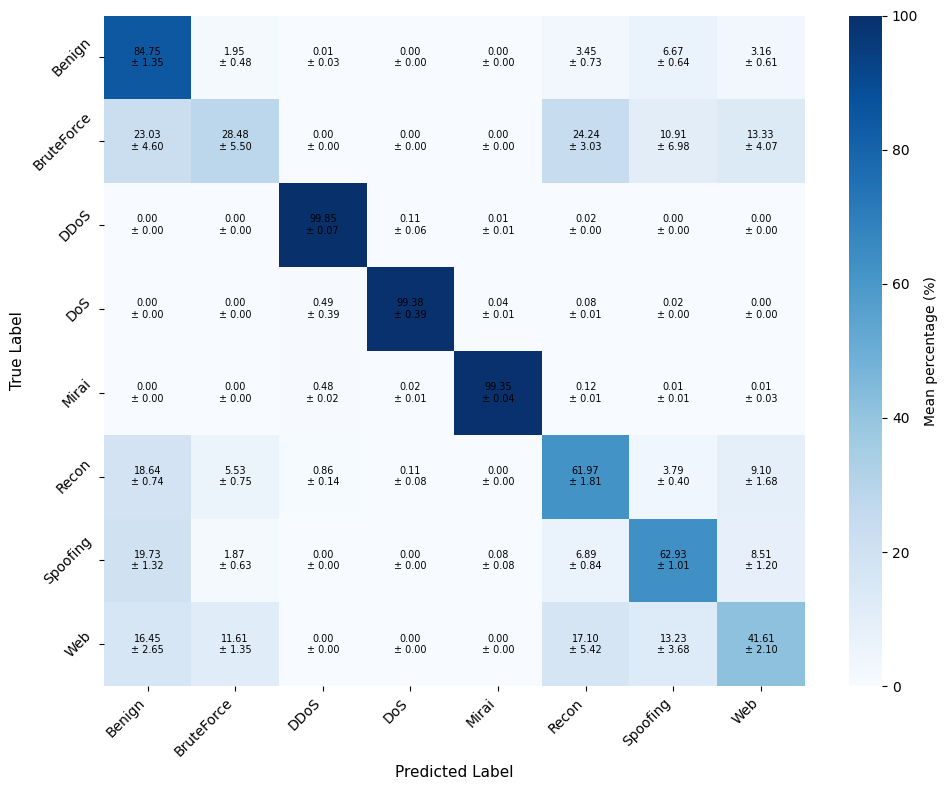

Saved the five-seed DNN normalized confusion matrix mean ± sample SD.


In [18]:
# ============================================================
# Five-seed normalized confusion matrix: mean ± sample SD
# ============================================================

# One final matrix is produced. Individual seed matrices are
# calculated internally only to obtain the across-seed mean
# and sample standard deviation for each matrix cell.

labels = np.arange(number_of_classes)
class_names = label_encoder.classes_

normalized_confusion_matrices = []

# ------------------------------------------------------------
# Build one row-normalized confusion matrix per seed
# ------------------------------------------------------------
for candidate in representative_candidates:

    seed_predictions = candidate["Predictions"]

    seed_cm = confusion_matrix(
        y_test,
        seed_predictions,
        labels=labels,
    )

    row_totals = seed_cm.sum(
        axis=1,
        keepdims=True,
    )

    seed_cm_normalized = np.divide(
        seed_cm,
        row_totals,
        out=np.zeros_like(
            seed_cm,
            dtype=float,
        ),
        where=row_totals != 0,
    )

    normalized_confusion_matrices.append(
        seed_cm_normalized
    )

normalized_confusion_matrices = np.stack(
    normalized_confusion_matrices,
    axis=0,
)

if normalized_confusion_matrices.shape[0] != len(RUN_SEEDS):
    raise ValueError(
        "The number of confusion matrices does not match "
        "the number of final-run seeds."
    )

# ------------------------------------------------------------
# Cell-wise mean and sample SD across the five seeds
# ------------------------------------------------------------
mean_cm = np.mean(
    normalized_confusion_matrices,
    axis=0,
)

sd_cm = np.std(
    normalized_confusion_matrices,
    axis=0,
    ddof=1,
)

# Convert proportions to percentages.
mean_cm_pct = mean_cm * 100.0
sd_cm_pct = sd_cm * 100.0

# ------------------------------------------------------------
# Save numerical mean and SD matrices
# ------------------------------------------------------------
mean_cm_df = pd.DataFrame(
    mean_cm_pct,
    index=class_names,
    columns=class_names,
)

sd_cm_df = pd.DataFrame(
    sd_cm_pct,
    index=class_names,
    columns=class_names,
)

mean_cm_df.index.name = "True_Label"
mean_cm_df.columns.name = "Predicted_Label"

sd_cm_df.index.name = "True_Label"
sd_cm_df.columns.name = "Predicted_Label"

mean_cm_df.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "dnn_normalized_confusion_matrix_5_seed_mean.csv"
)

sd_cm_df.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "dnn_normalized_confusion_matrix_5_seed_sd.csv"
)

# ------------------------------------------------------------
# Save combined mean ± SD table
# ------------------------------------------------------------
mean_sd_table = pd.DataFrame(
    index=class_names,
    columns=class_names,
    dtype=object,
)

for i in range(number_of_classes):
    for j in range(number_of_classes):
        mean_sd_table.iloc[i, j] = (
            f"{mean_cm_pct[i, j]:.2f} "
            f"± {sd_cm_pct[i, j]:.2f}"
        )

mean_sd_table.index.name = "True_Label"
mean_sd_table.columns.name = "Predicted_Label"

mean_sd_table.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "dnn_normalized_confusion_matrix_5_seed_mean_sd.csv"
)

# ------------------------------------------------------------
# Plot ONE final mean ± SD normalized confusion matrix
# ------------------------------------------------------------
plt.figure(
    figsize=(10, 8)
)

ax = sns.heatmap(
    mean_cm_pct,
    annot=False,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0,
    vmax=100,
    cbar_kws={
        "label": "Mean percentage (%)"
    },
)

for i in range(number_of_classes):
    for j in range(number_of_classes):
        ax.text(
            j + 0.5,
            i + 0.5,
            (
                f"{mean_cm_pct[i, j]:.2f}"
                f"\n± {sd_cm_pct[i, j]:.2f}"
            ),
            ha="center",
            va="center",
            fontsize=7,
        )

plt.xlabel(
    "Predicted Label",
    fontsize=11,
)

plt.ylabel(
    "True Label",
    fontsize=11,
)

plt.xticks(
    rotation=45,
    ha="right",
)

plt.yticks(
    rotation=45,
)

plt.tight_layout()

plt.savefig(
    REPORT_OUTPUT_DIRECTORY
    / "dnn_normalized_confusion_matrix_5_seed_mean_sd.pdf",
    bbox_inches="tight",
)

plt.savefig(
    REPORT_OUTPUT_DIRECTORY
    / "dnn_normalized_confusion_matrix_5_seed_mean_sd.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()

print(
    "Saved the five-seed DNN normalized confusion "
    "matrix mean ± sample SD."
)


In [19]:
import shutil

# Compress the entire Kaggle working/output directory
shutil.make_archive(
    "/kaggle/working/Balanced_Feature-AugmentedCICIoT2023_DNN_5Seed_V3",
    "zip",
    "/kaggle/working"
)

print("Created: /kaggle/working/Balanced_Feature-AugmentedCICIoT2023_DNN_5Seed_V3.zip")

Created: /kaggle/working/Balanced_Feature-AugmentedCICIoT2023_DNN_5Seed_V3.zip


## Offline inference timing with pretrained DNN models


In [ ]:
# ============================================================
# Offline classifier inference timing using pretrained DNN models
# ============================================================
# Reproduces classifier-only inference timing without retraining.
# Model loading and preprocessing are excluded from timed regions.
# ============================================================

import time
import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path

RESULT_DIRECTORY = REPORT_OUTPUT_DIRECTORY

X_test_offline = np.load(
    RESULT_DIRECTORY / "X_test_model_input.npy"
)

RUN_SEEDS_OFFLINE = [42, 43, 44, 45, 46]
N_WARMUP_RUNS_OFFLINE = 3
N_TIMING_RUNS_OFFLINE = 5
N_TEST_SAMPLES = len(X_test_offline)

offline_timing_records = []

for run_index, seed in enumerate(
    RUN_SEEDS_OFFLINE,
    start=1,
):
    model_path = (
        RESULT_DIRECTORY
        / f"DNN_Seed_{run_index}"
        / f"dnn_seed_{seed}.keras"
    )

    model = tf.keras.models.load_model(
        model_path,
        custom_objects={
            "SparseMacroF1": SparseMacroF1,
        },
    )

    for _ in range(N_WARMUP_RUNS_OFFLINE):
        _ = model.predict(
            X_test_offline,
            verbose=0,
        )

    for repetition in range(1, N_TIMING_RUNS_OFFLINE + 1):
        start_time = time.perf_counter()
        _ = model.predict(
            X_test_offline,
            verbose=0,
        )
        inference_time_s = time.perf_counter() - start_time

        offline_timing_records.append(
            {
                "Seed": seed,
                "Run": run_index,
                "Repetition": repetition,
                "Inference_Time_s": inference_time_s,
                "Latency_ms_per_sample": (
                    inference_time_s / N_TEST_SAMPLES * 1000.0
                ),
                "Throughput_samples_per_s": (
                    N_TEST_SAMPLES / inference_time_s
                ),
            }
        )

    del model
    tf.keras.backend.clear_session()

offline_timing_df = pd.DataFrame(
    offline_timing_records
)

offline_timing_df.to_csv(
    RESULT_DIRECTORY / "offline_inference_timing_repetitions.csv",
    index=False,
)

offline_seed_summary = (
    offline_timing_df
    .groupby("Seed", as_index=False)
    .agg(
        Mean_Inference_Time_s=("Inference_Time_s", "mean"),
        SD_Inference_Time_s=("Inference_Time_s", "std"),
        Mean_Latency_ms_per_sample=("Latency_ms_per_sample", "mean"),
        SD_Latency_ms_per_sample=("Latency_ms_per_sample", "std"),
        Mean_Throughput_samples_per_s=("Throughput_samples_per_s", "mean"),
    )
)

offline_seed_summary.to_csv(
    RESULT_DIRECTORY / "offline_inference_timing_per_seed.csv",
    index=False,
)

offline_final_summary = pd.DataFrame(
    {
        "Metric": [
            "Inference_Time_s",
            "Latency_ms_per_sample",
            "Throughput_samples_per_s",
        ],
        "Mean": [
            offline_seed_summary["Mean_Inference_Time_s"].mean(),
            offline_seed_summary["Mean_Latency_ms_per_sample"].mean(),
            offline_seed_summary["Mean_Throughput_samples_per_s"].mean(),
        ],
        "SD": [
            offline_seed_summary["Mean_Inference_Time_s"].std(ddof=1),
            offline_seed_summary["Mean_Latency_ms_per_sample"].std(ddof=1),
            offline_seed_summary["Mean_Throughput_samples_per_s"].std(ddof=1),
        ],
    }
)

offline_final_summary.to_csv(
    RESULT_DIRECTORY / "offline_inference_timing_summary.csv",
    index=False,
)

print("Offline DNN inference timing completed.")
display(offline_seed_summary)
display(offline_final_summary)
